# Transfer learning | ImageNet CNNs
**Member 4 · Mahij Khantigiri Gosai**

We compare four pretrained CNN architectures using the same fixed UrbanSound8K split and input representation as the team's custom CNN. This notebook reads the recorded training evidence and does not retrain models or evaluate fold 10.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image
ROOT = Path.cwd()
if not (ROOT / 'reports').exists():
    ROOT = ROOT.parent
assert (ROOT / 'reports/member4/model_comparison.csv').exists()
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
import json
base = json.loads((ROOT/'reports/member4/baseline_reference.json').read_text())
split = json.loads((ROOT/'reports/member4/split_audit.json').read_text())
display(pd.DataFrame(split).T)
results = pd.read_csv(ROOT/'reports/member4/model_comparison.csv')
print(f"{len(results)} completed ImageNet training runs; validation reference: {base['accuracy']:.2f}%")


,clips,source_ids,folds
train,7000,1048,"[1, 2, 3, 4, 5, 6, 7, 8]"
validation,816,125,[9]
test,837,124,[10]


21 completed ImageNet training runs; validation reference: 86.89%


## 1. Architecture and adaptation
All models use the unresized 128 × 173 log-Mel representation, replicated into three channels, with ImageNet normalization. A new dropout and ten-class linear head replaces the pretrained classifier. Frozen, partial and full stages progressively expose backbone parameters to training.

stage,frozen,partial,gain_pp
arch,,,
densenet121,76.72,83.82,7.11
efficientnet_b0,81.37,83.33,1.96
mobilenet_v2,77.57,85.29,7.72
resnet18,75.49,85.17,9.68


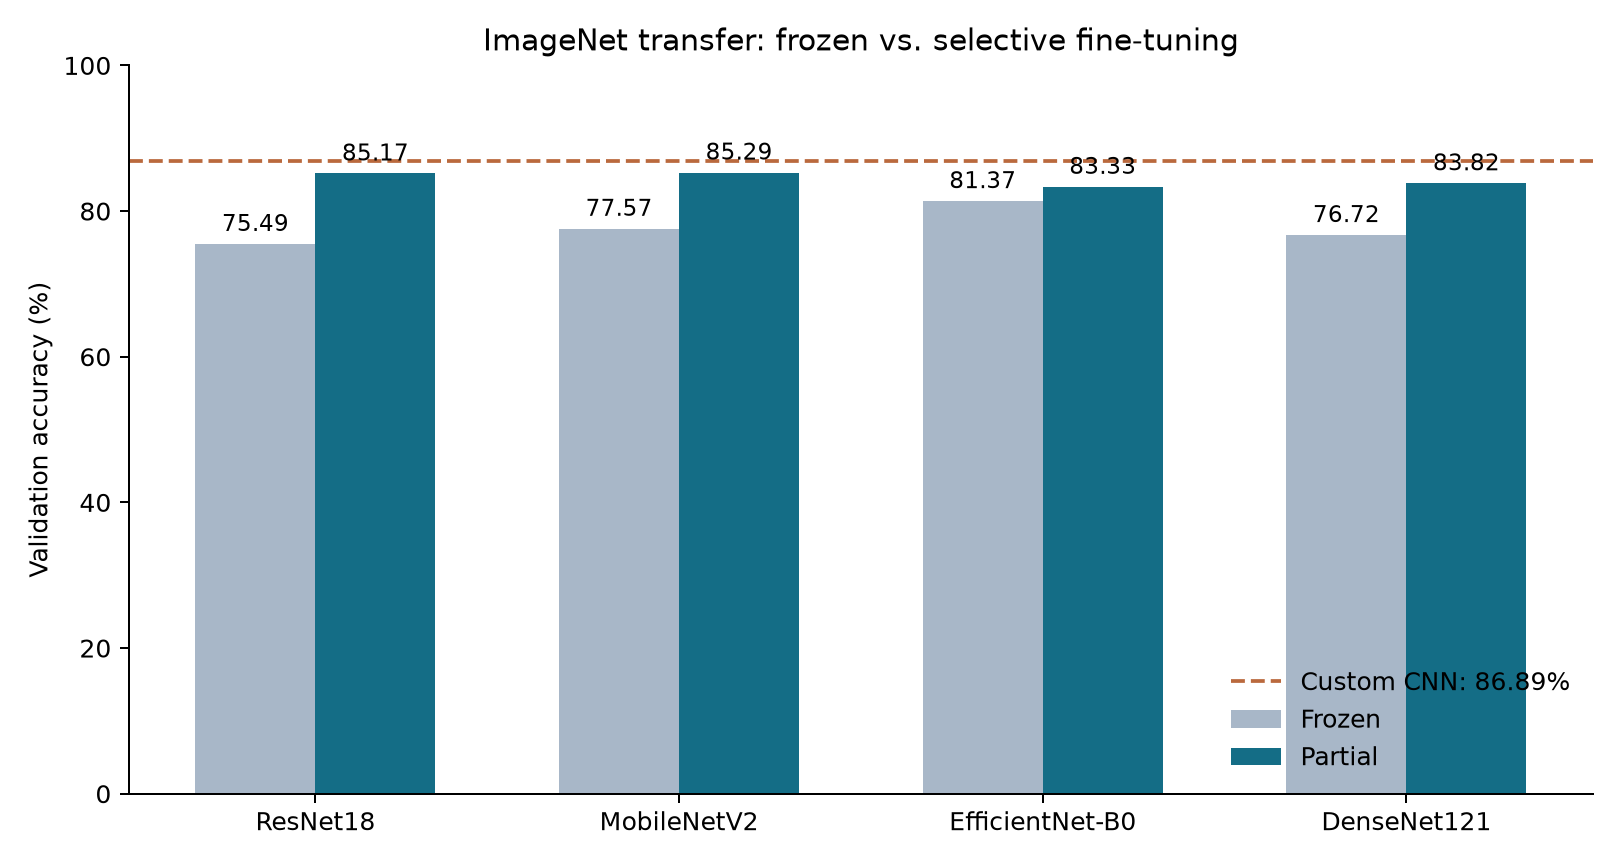

In [2]:
runs = results[results.seed.eq(42) & results.name.str.endswith(('_frozen','_partial'))]
stages = runs.pivot(index='arch', columns='stage', values='accuracy')[['frozen','partial']]
stages['gain_pp'] = stages.partial - stages.frozen
display(stages.round(2))
display(Image(filename=str(ROOT/'figures/transfer/submission_stage_comparison.png')))


## 2. Fine-tuning and selected checkpoint
The strongest individual ImageNet model is regularized ResNet18 (seed 2024). The recorded checkpoints are selected by validation accuracy and lower validation loss in case of ties.

,name,stage,seed,accuracy,macro_f1,best_epoch,training_seconds
0,resnet18_repeat_full_2024,full,2024,87.500,88.675,15,380.564
1,resnet18_opt_regularized,full,42,87.010,88.025,16,379.690
2,resnet18_opt_higher_lr,full,42,86.642,87.459,6,227.445
3,mobilenet_v2_opt_mixup,full,42,86.397,87.874,10,203.165
4,mobilenet_v2_opt_regularized,full,42,86.397,87.378,12,222.823
5,mobilenet_v2_full,full,42,86.275,87.587,10,196.069
6,mobilenet_v2_opt_higher_lr,full,42,86.029,87.409,12,219.543
7,resnet18_repeat_full_123,full,123,85.539,86.930,15,373.462
8,mobilenet_v2_partial,partial,42,85.294,86.341,12,86.202
9,resnet18_partial,partial,42,85.172,86.771,3,56.249


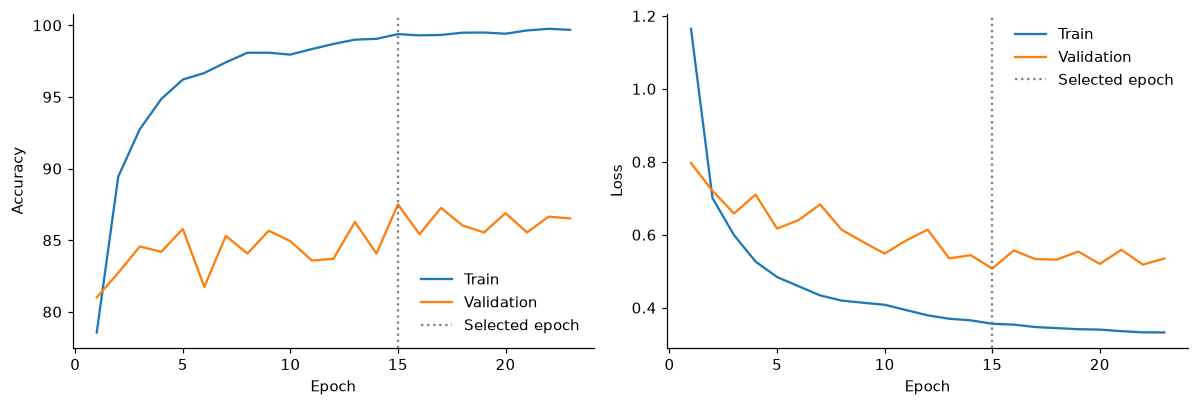

In [3]:
cols = ['name','stage','seed','accuracy','macro_f1','best_epoch','training_seconds']
display(results[cols].head(10).round(3))
run = results.iloc[0]['name']
history = pd.read_csv(ROOT/'reports/member4'/run/'training_history.csv')
fig, ax = plt.subplots(1,2,figsize=(11,3.8))
for a,m in zip(ax,['accuracy','loss']):
    a.plot(history.epoch,history['train_'+m],label='Train')
    a.plot(history.epoch,history['val_'+m],label='Validation')
    a.axvline(results.iloc[0].best_epoch,color='gray',linestyle=':',label='Selected epoch')
    a.set(xlabel='Epoch',ylabel=m.title()); a.legend(frameon=False)
fig.tight_layout()
plt.show()


## 3. Computational cost and reproducibility

,run,parameters,estimated_macs,latency_ms,checkpoint_mib
0,resnet18_repeat_full_2024,11181642,834909696,2.994,42.725
1,resnet18_opt_regularized,11181642,834909696,3.287,42.725
2,mobilenet_v2_opt_mixup,2236682,149506560,5.511,8.751
3,densenet121_partial,6964106,1295247360,12.400,27.106
4,efficientnet_b0_partial,4020358,191178496,6.846,15.605


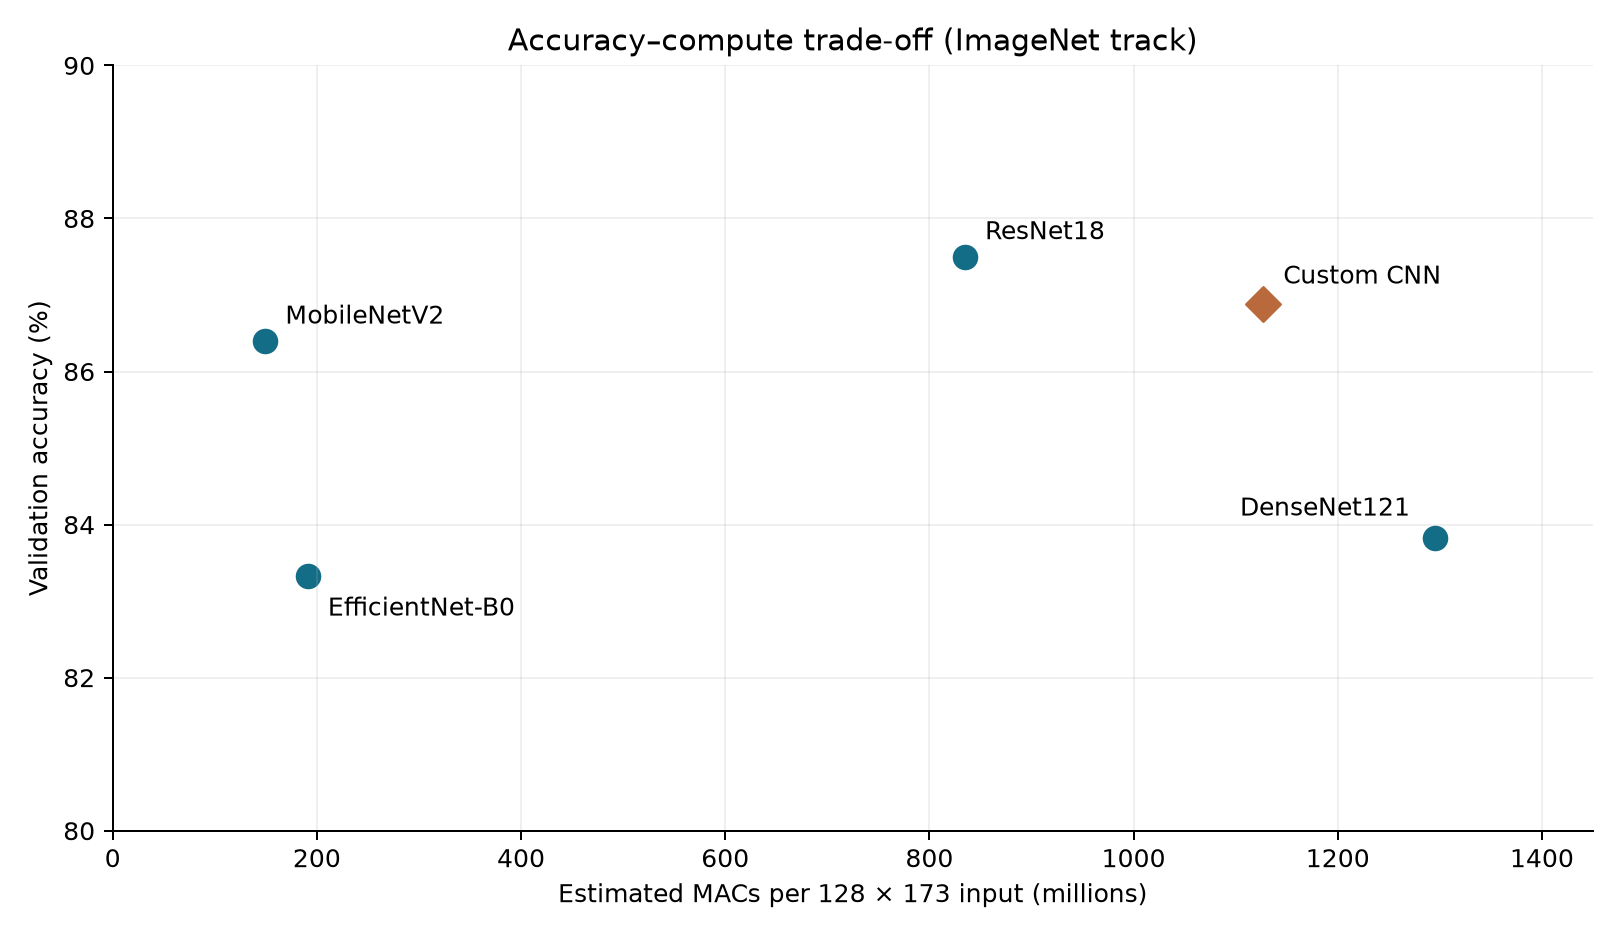

,name,seed,accuracy,macro_f1
0,resnet18_opt_regularized,42,87.010,88.025
1,resnet18_repeat_full_2024,2024,87.500,88.675
2,resnet18_repeat_full_123,123,85.539,86.930


,Unnamed: 0,accuracy,macro_f1
0,mean,86.683,87.877
1,std,1.020,0.882


In [4]:
bench = pd.read_csv(ROOT/'reports/member4/final_benchmark.csv')
display(bench[bench.input_shape.eq('1x128x173')][['run','parameters','estimated_macs','latency_ms','checkpoint_mib']].round(3))
display(Image(filename=str(ROOT/'figures/transfer/submission_efficiency.png')))
display(pd.read_csv(ROOT/'reports/member4/seed_comparison.csv').round(3))
display(pd.read_csv(ROOT/'reports/member4/seed_statistics.csv').round(3))


## 4. Selected model: class-level results

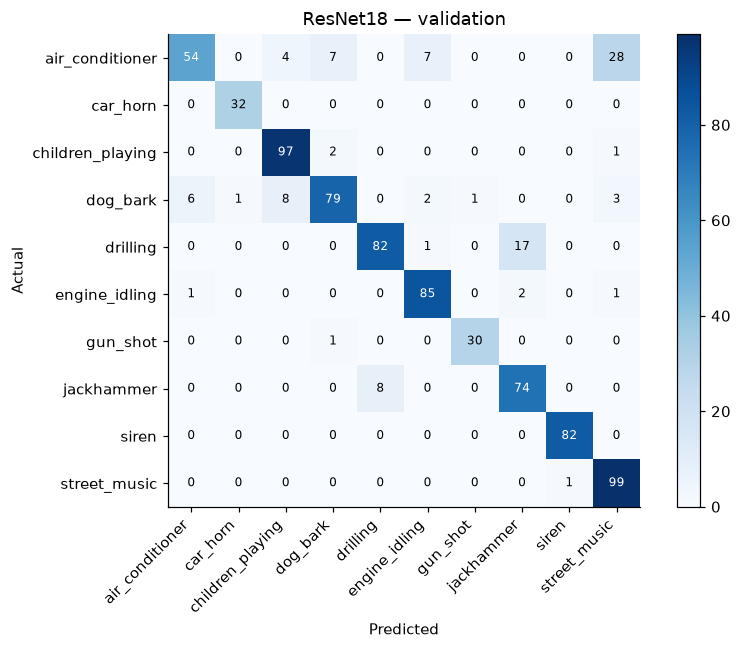

,precision,recall,f1-score,support
air_conditioner,0.885,0.540,0.671,100.000
car_horn,0.970,1.000,0.985,32.000
children_playing,0.890,0.970,0.928,100.000
dog_bark,0.888,0.790,0.836,100.000
drilling,0.911,0.820,0.863,100.000
engine_idling,0.895,0.955,0.924,89.000
gun_shot,0.968,0.968,0.968,31.000
jackhammer,0.796,0.902,0.846,82.000
siren,0.988,1.000,0.994,82.000
street_music,0.750,0.990,0.853,100.000


In [5]:
cm = pd.read_csv(ROOT/'reports/member4/resnet18_repeat_full_2024_confusion.csv',index_col=0)
fig,ax=plt.subplots(figsize=(8,6))
im=ax.imshow(cm,cmap='Blues')
ax.set_xticks(range(len(cm)),cm.columns,rotation=45,ha='right')
ax.set_yticks(range(len(cm)),cm.index)
ax.set(xlabel='Predicted',ylabel='Actual',title='ResNet18 — validation')
for i in range(len(cm)):
    for j in range(len(cm)):
        ax.text(j,i,str(cm.iloc[i,j]),ha='center',va='center',color='white' if cm.iloc[i,j]>cm.values.max()/2 else 'black',fontsize=8)
fig.colorbar(im,ax=ax); fig.tight_layout(); plt.show()
display(pd.read_csv(ROOT/'reports/member4/resnet18_repeat_full_2024_class_metrics.csv',index_col=0).round(3))


## Conclusion
ResNet18 achieves 87.50% validation accuracy versus 86.89% for the existing custom CNN. Its three-seed average is 86.68%, so the best-run gain is not a robust improvement. MobileNetV2 is the smaller checkpoint and lower-MAC alternative. We retain the held-out test fold for the team's final evaluation. See the [submission report](../reports/member4_report.md) and [reproduction guide](../reports/member4/README.md).